# Evaluate the saved WRN-28-56 models (no training)

This notebook re-runs **only evaluation** on the checkpoints that `Colab_Training.ipynb` already saved to Google Drive,
so the final accuracy, parameter count, and training curves are visible as notebook output. It does not train
anything and takes a few minutes on a Colab GPU.

It expects the same Drive layout as `Colab_Training.ipynb`:
`MyDrive/cifar_resnet_project/{data.zip, runs/main/, runs/baseline/, runs/final/}`.

Steps:
1. Load the repository, check the GPU, and print the trainable parameter count.
2. Rebuild the data cache from the original `data.zip`.
3. Re-evaluate the development checkpoints (`runs/main/best.pt`, `runs/baseline/best.pt`) on their held-out
   5,000-image validation split.
4. Plot the recorded training curves (`history.jsonl`).
5. Regenerate the submission from the final full-data checkpoint and check that it matches the file submitted to Kaggle.

## 1. Mount Drive and locate the saved runs

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import os, sys, json, subprocess, hashlib

PROJECT = Path('/content/drive/MyDrive/cifar_resnet_project')   # change if your folder has another name
DATA_ZIP = PROJECT / 'data.zip'
RUNS = PROJECT / 'runs'
WORKERS = 4

assert DATA_ZIP.is_file(), f'data.zip not found in {PROJECT}'
for name in ['main/best.pt', 'main/history.jsonl', 'baseline/best.pt', 'baseline/history.jsonl', 'final/final.pt']:
    path = RUNS / name
    print(f"{'found  ' if path.is_file() else 'MISSING'}  {path}")

Mounted at /content/drive
found    /content/drive/MyDrive/cifar_resnet_project/runs/main/best.pt
found    /content/drive/MyDrive/cifar_resnet_project/runs/main/history.jsonl
found    /content/drive/MyDrive/cifar_resnet_project/runs/baseline/best.pt
found    /content/drive/MyDrive/cifar_resnet_project/runs/baseline/history.jsonl
found    /content/drive/MyDrive/cifar_resnet_project/runs/final/final.pt


## 2. Load the code and check the GPU

In [2]:
LOCAL = Path('/content/cifar_competition'); LOCAL.mkdir(exist_ok=True)
REPO = LOCAL / 'cifar-resnet-colab'
if not (REPO / 'src').is_dir():
    subprocess.run(['git', 'clone', 'https://github.com/mj3664-web/cifar-resnet-colab.git', str(REPO)], check=True)
os.chdir(REPO); sys.path.insert(0, str(REPO))

import torch, torchvision
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU is fine, only slower)')
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)

def run_module(module, *args):
    command = [sys.executable, '-u', '-m', module, *map(str, args)]
    print('Running:', ' '.join(command), flush=True)
    subprocess.run(command, check=True)

from src.model import build_model
config = json.loads((REPO / 'configs/main.json').read_text())
model = build_model(config)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'WRN-{config["model"]["depth"]}-{config["model"]["base_width"]} trainable parameters: {n_params:,}')
assert n_params <= 5_000_000
del model

GPU: none (CPU is fine, only slower)
PyTorch: 2.14.1+cpu | torchvision: 0.29.1+cpu
WRN-28-56 trainable parameters: 4,480,474


## 3. Rebuild the data cache from the original archive

In [3]:
import shutil
CACHE = LOCAL / 'cache'
shutil.copy2(DATA_ZIP, LOCAL / 'data.zip')
run_module('src.data', '--zip', LOCAL / 'data.zip', '--out', CACHE)
manifest = json.loads((CACHE / 'manifest.json').read_text())
print('train images:', manifest['train_count'], '| test images:', manifest['test_count'])

Running: /usr/bin/python3 -u -m src.data --zip /content/cifar_competition/data.zip --out /content/cifar_competition/cache
train images: 50000 | test images: 2000


## 4. Held-out validation accuracy of the development runs
Each `best.pt` was trained on 45,000 images; the remaining 5,000 (stratified, split seed 2026) were never trained on.

In [4]:
for run in ['main', 'baseline']:
    ckpt = RUNS / run / 'best.pt'
    if ckpt.is_file():
        print(f'===== {run} =====')
        run_module('src.evaluate', '--data', CACHE, '--checkpoint', ckpt, '--workers', WORKERS)
    else:
        print(f'{run}: best.pt not found, skipped')

===== main =====
Running: /usr/bin/python3 -u -m src.evaluate --data /content/cifar_competition/cache --checkpoint /content/drive/MyDrive/cifar_resnet_project/runs/main/best.pt --workers 4
===== baseline =====
Running: /usr/bin/python3 -u -m src.evaluate --data /content/cifar_competition/cache --checkpoint /content/drive/MyDrive/cifar_resnet_project/runs/baseline/best.pt --workers 4


## 5. Training curves recorded during training

main: best EMA validation accuracy 97.36% at epoch 365
baseline: best EMA validation accuracy 96.98% at epoch 270


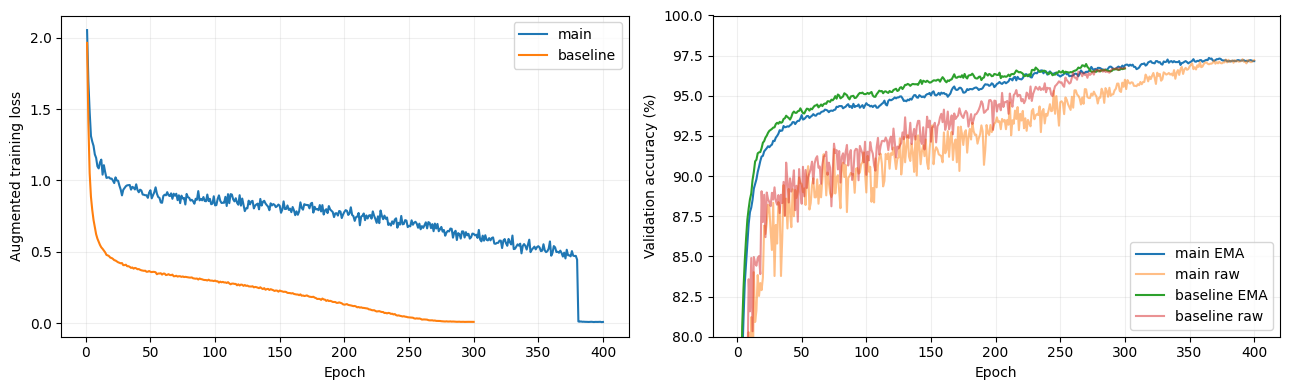

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for run in ['main', 'baseline']:
    log = RUNS / run / 'history.jsonl'
    if not log.is_file():
        continue
    rows = [json.loads(s) for s in log.read_text().splitlines()]
    ep = [r['epoch'] for r in rows]
    axes[0].plot(ep, [r['train_loss'] for r in rows], label=run)
    axes[1].plot(ep, [100 * r['ema_accuracy'] for r in rows], label=f'{run} EMA')
    axes[1].plot(ep, [100 * r['raw_accuracy'] for r in rows], alpha=.5, label=f'{run} raw')
    best = max(rows, key=lambda r: r['ema_accuracy'])
    print(f"{run}: best EMA validation accuracy {100*best['ema_accuracy']:.2f}% at epoch {best['epoch']}")
axes[0].set(xlabel='Epoch', ylabel='Augmented training loss')
axes[1].set(xlabel='Epoch', ylabel='Validation accuracy (%)', ylim=(80, 100))
for ax in axes: ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.show()

## 6. Final model: regenerate the Kaggle submission
`runs/final/final.pt` was retrained from scratch on all 50,000 images (EMA weights, flip TTA). Its validation accuracy is not
meaningful because it has seen the validation images, so it is judged by the Kaggle score.
If the hash differs, a handful of predictions changed because GPU arithmetic is not bit-for-bit reproducible across hardware.

In [8]:
SUBMITTED_SHA = 'e0002d9308d4dbda8c5ba6b6a6b2ed85746bc78a4d32fb5b49f9570fcb5fba8f'   # file submitted to Kaggle
CHECK = LOCAL / "submission_check" / "submission.csv"
CHECK.parent.mkdir(parents=True, exist_ok=True)
run_module('src.predict', '--data', CACHE, '--checkpoint', RUNS / 'final' / 'final.pt', '--out', CHECK, '--workers', WORKERS)
sha = hashlib.sha256(CHECK.read_bytes()).hexdigest()
print('Regenerated submission SHA-256:', sha)
print('Identical to the submitted file:', sha == SUBMITTED_SHA)

Running: /usr/bin/python3 -u -m src.predict --data /content/cifar_competition/cache --checkpoint /content/drive/MyDrive/cifar_resnet_project/runs/final/final.pt --out /content/cifar_competition/submission_check/submission.csv --workers 4
Regenerated submission SHA-256: e0002d9308d4dbda8c5ba6b6a6b2ed85746bc78a4d32fb5b49f9570fcb5fba8f
Identical to the submitted file: True


## 7. Summary

In [9]:
print(f'Final model           : WRN-28-56 (pre-activation, widths 56/112/224, 4 blocks per stage)')
print(f'Trainable parameters  : {n_params:,}')
print(f'Validation accuracy   : see section 4 (main recipe, EMA weights, flip TTA)')
print(f'Kaggle public accuracy: 0.897')

Final model           : WRN-28-56 (pre-activation, widths 56/112/224, 4 blocks per stage)
Trainable parameters  : 4,480,474
Validation accuracy   : see section 4 (main recipe, EMA weights, flip TTA)
Kaggle public accuracy: 0.897
